##이미지의 픽셀 알아보기



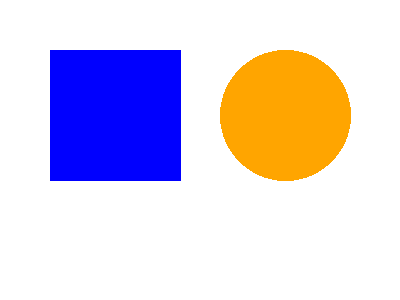

이미지 크기: (400, 300)
색상 모드: RGB
픽셀 색상: (0, 0, 255)


In [35]:

"""이미지 픽셀 알아보기"""

from PIL import Image, ImageDraw
from IPython.display import display

# 테스트용 이미지 만들기
img = Image.new("RGB", (400, 300), "white")
draw = ImageDraw.Draw(img)

draw.rectangle((50, 50, 180, 180), fill="blue")
draw.ellipse((220, 50, 350, 180), fill="orange")

display(img)

# 이미지 정보 확인하기
print("이미지 크기:", img.size)
print("색상 모드:", img.mode)
print("픽셀 색상:", img.getpixel((100, 100)))


##이미지 파일 불러오기 & 원하는 부분의 색 변경하기


### 1.이미지 구글 드라이브에 저장하기

In [36]:
from google.colab import drive
drive.mount('/content/gdrive')

Drive already mounted at /content/gdrive; to attempt to forcibly remount, call drive.mount("/content/gdrive", force_remount=True).


In [37]:
import os

image_path = "/content/gdrive/MyDrive/PixelWizard/ChoiSan1.jpeg"

print("사진 파일 존재:", os.path.exists(image_path))


사진 파일 존재: True


### 2.이미지 불러오기 및 원하는 부분의 색 변경하기


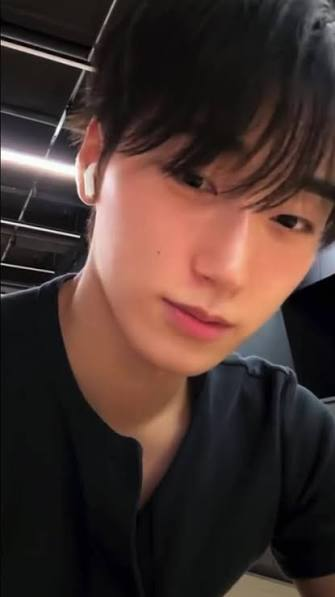

이미지 크기: (335, 597)
색상 모드: RGB


In [38]:
"""이미지 파일 직접 불러오기"""

from PIL import Image
from IPython.display import display

img = Image.open("/content/gdrive/MyDrive/PixelWizard/ChoiSan1.jpeg")

display(img)

print("이미지 크기:", img.size)
print("색상 모드:", img.mode)


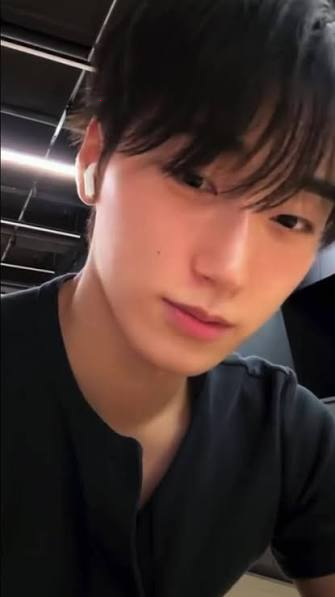

In [39]:
"""픽셀 하나의 색 바꾸기"""

img = img.convert("RGB")

# 원본 이미지를 복사해서 수정용 이미지 만들기
edited = img.copy()

# (100, 100) 위치의 픽셀 색상을 빨간색으로 변경
edited.putpixel((100, 100), (255, 0, 0))

display(edited)

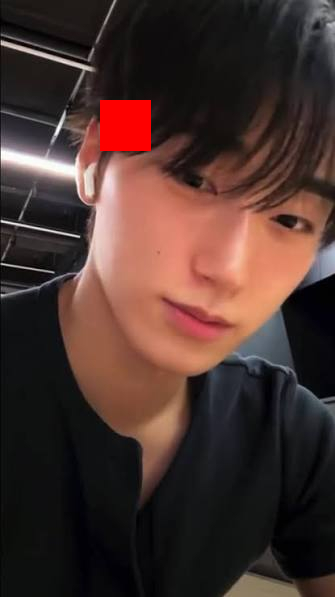

In [40]:
"""미션 : 빨간색 네모 만들기"""

from PIL import ImageDraw
from IPython.display import display

edited = img.copy()
draw = ImageDraw.Draw(edited)

draw.rectangle((100, 100, 150, 150), fill=(255, 0, 0))

display(edited)

##AI가 머리카락 구분하게 만들기


In [41]:
"""0. 실행 환경 확인하기 및 gpu로 runtime 변경하기"""

import torch

print("PyTorch 버전:", torch.__version__)
print("GPU 사용 가능:", torch.cuda.is_available())

PyTorch 버전: 2.11.0+cu130
GPU 사용 가능: True


In [42]:
"""1. AI 모델 설치하기"""

!pip install -q transformers accelerate

In [43]:
"""2. AI 모델로 머리카락 찾기"""

import torch
import torch.nn.functional as F
import numpy as np
from PIL import Image
from IPython.display import display
from transformers import (
    SegformerImageProcessor,
    SegformerForSemanticSegmentation
)

# 1. 모델 이름
model_name = "jonathandinu/face-parsing"

# 2. 이미지 처리 도구와 AI 모델 불러오기
processor = SegformerImageProcessor.from_pretrained(model_name)
model = SegformerForSemanticSegmentation.from_pretrained(model_name)

# 3. GPU가 있으면 GPU, 없으면 CPU 사용
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

# 4. 사진을 AI가 분석할 수 있는 형태로 변환
inputs = processor(images=img, return_tensors="pt")
inputs = {key: value.to(device) for key, value in inputs.items()}

# 5. AI가 사진의 각 영역을 예측
with torch.no_grad():
    outputs = model(**inputs)

# 6. 예측 결과를 원본 사진 크기에 맞춤
logits = F.interpolate(
    outputs.logits,
    size=(img.height, img.width),
    mode="bilinear",
    align_corners=False
)

# 7. 각 픽셀의 예측 결과 확인
predictions = logits.argmax(dim=1)[0].cpu().numpy()

print("모델이 구분하는 영역:")
print(model.config.id2label)

preprocessor_config.json:   0%|          | 0.00/374 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.69k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  339MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/1172 [00:00<?, ?it/s]

모델이 구분하는 영역:
{0: 'background', 1: 'skin', 2: 'nose', 3: 'eye_g', 4: 'l_eye', 5: 'r_eye', 6: 'l_brow', 7: 'r_brow', 8: 'l_ear', 9: 'r_ear', 10: 'mouth', 11: 'u_lip', 12: 'l_lip', 13: 'hair', 14: 'hat', 15: 'ear_r', 16: 'neck_l', 17: 'neck', 18: 'cloth'}


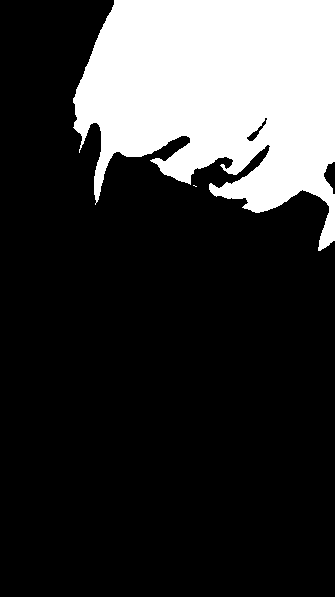

머리카락 마스크 생성 완료!


In [44]:
"""3. 머리카락 마스크 만들기"""

# AI 모델에서 머리카락에 해당하는 번호 찾기
hair_id = next(
    int(key)
    for key, value in model.config.id2label.items()
    if value.lower() == "hair"
)

# 머리카락은 흰색, 나머지는 검은색으로 표시
mask_array = (predictions == hair_id).astype(np.uint8) * 255

hair_mask = Image.fromarray(mask_array)
display(hair_mask)

print("머리카락 마스크 생성 완료!")

## 머리카락 색 바꾸기


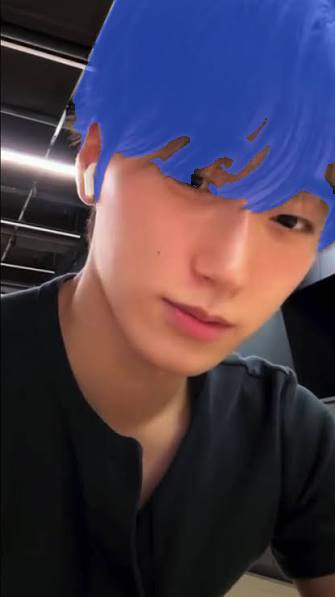

In [45]:
"""머리카락을 자연스러운 갈색으로 바꾸기"""

import numpy as np
from PIL import Image
from IPython.display import display

# 1. 원본 사진을 RGB 숫자 배열로 변환
original = np.array(img.convert("RGB"))

# 2. 머리카락 마스크를 숫자 배열로 변환
mask = np.array(hair_mask) > 0

# 3. 원본 사진을 복사해서 편집용 이미지 만들기
edited_array = original.copy()

# 4. 적용할 머리카락 색 정하기 (갈색)
new_color = np.array([50, 100, 255])

# 5. 머리카락 부분에만 새 색 적용하기
edited_array[mask] = (
    original[mask] * 0.4 + new_color * 0.6
).astype(np.uint8)

# 6. 결과를 이미지로 변환해서 확인하기
edited = Image.fromarray(edited_array)
display(edited)

## Improve the quality


### 1.새로운 AI 모델로 머리카락 인식 개선하기


In [46]:
%pip install -q mediapipe

In [47]:
"""새로운 AI 모델 다운로드 및 설정하기"""

import urllib.request
import mediapipe as mp

from mediapipe.tasks import python
from mediapipe.tasks.python import vision

model_url = (
    "https://storage.googleapis.com/mediapipe-models/"
    "image_segmenter/hair_segmenter/float32/latest/"
    "hair_segmenter.tflite"
)

model_path = "/content/hair_segmenter.tflite"

urllib.request.urlretrieve(model_url, model_path)

options = vision.ImageSegmenterOptions(
    base_options=python.BaseOptions(
        model_asset_path=model_path
    ),
    output_confidence_masks=True
)

In [48]:
"""사진에서 머리카락 영역 예측하기"""

import numpy as np

image_array = np.array(img.convert("RGB"))

mp_image = mp.Image(
    image_format=mp.ImageFormat.SRGB,
    data=image_array
)

with vision.ImageSegmenter.create_from_options(options) as segmenter:
    result = segmenter.segment(mp_image)

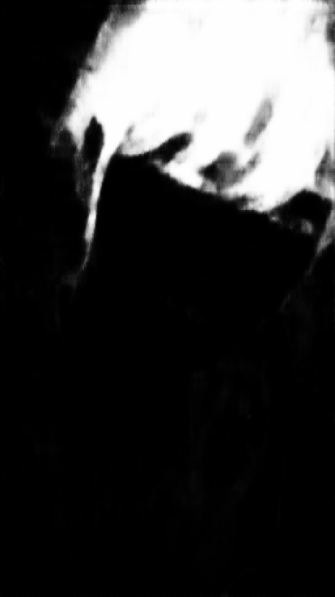

In [49]:
"""머리카락 확률 마스크 만들기"""

from PIL import Image
from IPython.display import display

hair_probability = np.squeeze(
    result.confidence_masks[1].numpy_view()
)

hair_probability = np.clip(
    hair_probability, 0, 1
)

mask_array = (
    hair_probability * 255
).astype(np.uint8)

hair_mask = Image.fromarray(mask_array)

display(hair_mask)

기준값: 0.5


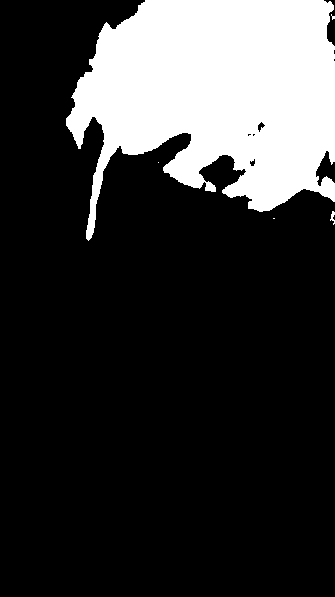

기준값: 0.65


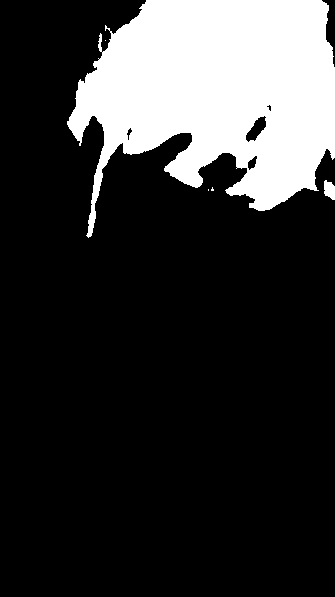

기준값: 0.8


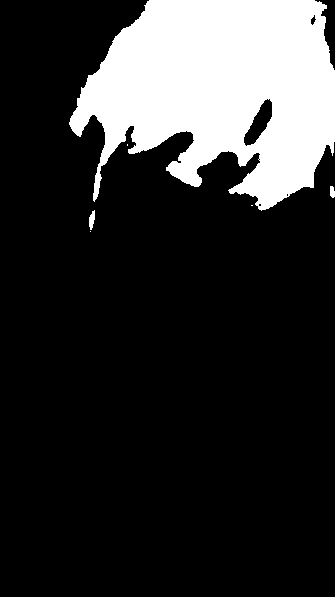

In [50]:
"""기준값(Threshold)에 따른 결과 비교"""

for threshold in [0.5, 0.65, 0.8]:
    mask = (
        hair_probability >= threshold
    ).astype(np.uint8) * 255

    print(f"기준값: {threshold}")
    display(Image.fromarray(mask))


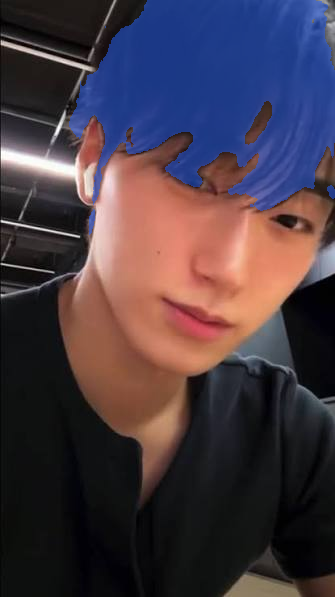

In [63]:
"""원본 사진에 마스크 겹쳐 보기"""

import numpy as np
from PIL import Image
from IPython.display import display

# 원본 사진을 숫자 배열로 변환
original = np.array(img.convert("RGB")).astype(np.float32)

# 머리카락 판정 기준
threshold = 0.75
mask = hair_probability >= threshold

# 원본을 복사해 미리보기 이미지 생성
preview = original.copy()

# 파란색으로 표시할 영역
blue = np.array([40, 100, 255], dtype=np.float32)

# 선택된 영역에 원본 색상과 파란색을 절반씩 섞기
preview[mask] = (
    original[mask] * 0.5
    + blue * 0.5
)

# 이미지로 변환할 수 있도록 0~255 정수 형식으로 변경
preview = np.clip(preview, 0, 255).astype(np.uint8)

display(Image.fromarray(preview))


### 2.머리카락 마스크 보정하기

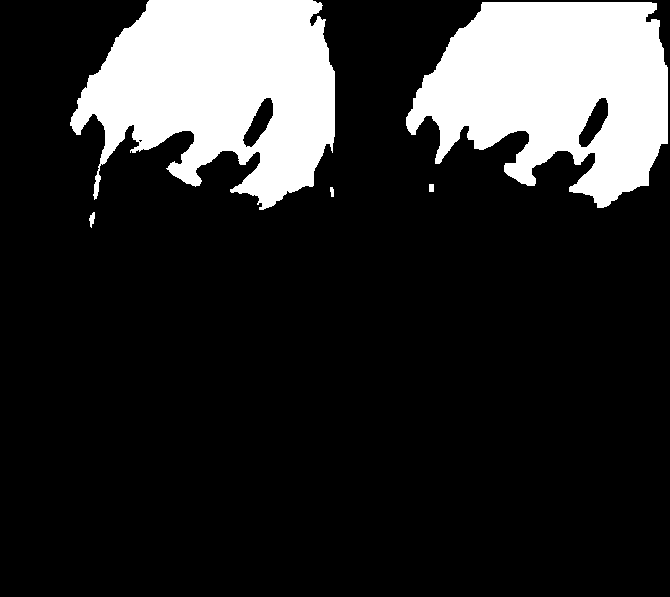

In [64]:
import numpy as np
from PIL import Image
from IPython.display import display
from scipy import ndimage

# 머리카락 확률이 높은 영역만 선택
hair_candidate = hair_probability >= 0.85

# 작은 잡음 제거 및 머리카락 영역 정리
structure = np.ones((5, 5), dtype=bool)
refined_mask = ndimage.binary_opening(
    hair_candidate, structure=structure
)
refined_mask = ndimage.binary_closing(
    refined_mask, structure=structure
)

# 최종 마스크
after_mask = refined_mask.copy()

# 전후 마스크 비교
comparison = Image.new("RGB", (img.width * 2, img.height))
comparison.paste(
    Image.fromarray(hair_candidate.astype(np.uint8) * 255),
    (0, 0)
)
comparison.paste(
    Image.fromarray(after_mask.astype(np.uint8) * 255),
    (img.width, 0)
)

display(comparison)

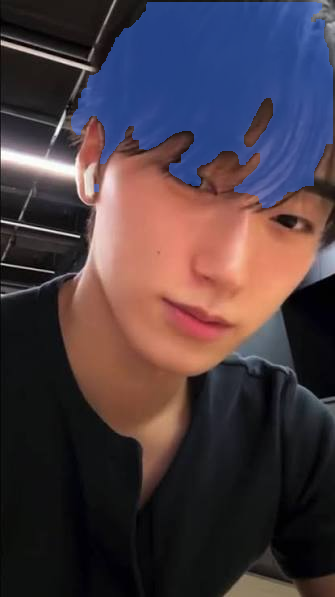

In [65]:
"""개선된 마스크를 머리카락 색상 변경 코드에 연결하기 """

# 최종 머리카락 마스크
final_hair_mask = after_mask.copy()

# 원본 이미지
original_rgb = np.array(img.convert("RGB"))

#색상을 변경할 이미지 복사본
preview = original_rgb.copy()

#테스트용 파란색(RGB)
blue = np.array([60, 120, 255], dtype = np.float32)

#선택된 머리카락 영역에 색상 적용
preview[final_hair_mask] = (
    original_rgb[final_hair_mask].astype(np.float32) * 0.5
    + blue * 0.5
).astype(np.uint8)

# 결과 표시
display(Image.fromarray(preview))

### 3.눈동자로 인식되는 부분 제외시키기
단, 이 코드는 지금 실험하는 이미지 파일에만 해당함

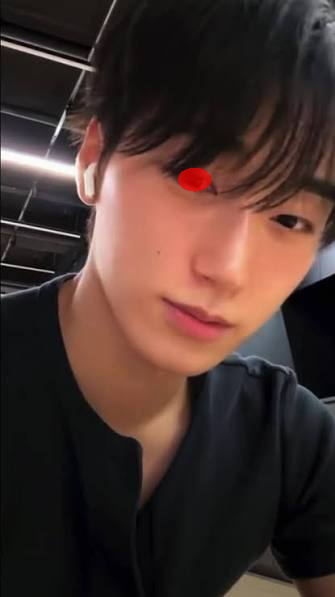

In [93]:
""" 눈동자 좌표 찾기"""

import numpy as np
from PIL import Image
from IPython.display import display

# 원본 사진
original = np.array(img.convert("RGB")).copy()
h, w = original.shape[:2]

# 좌표 계산
yy, xx = np.mgrid[0:h, 0:w]
x = xx / w
y = yy / h

# 타원 위치와 크기
cx, cy = 0.58, 0.30 #cx:타원좌우 cy: 타원위아래
rx, ry = 0.05, 0.020 # 타원의 가로 세로

# 타원 영역 만들기
eye_area = ((x - cx) / rx)**2 + ((y - cy) / ry)**2 <= 1

# 타원 내부를 빨간색으로 표시
original[eye_area] = (
    original[eye_area] * 0.3
    + np.array([255, 0, 0]) * 0.7
).astype(np.uint8)

display(Image.fromarray(original))

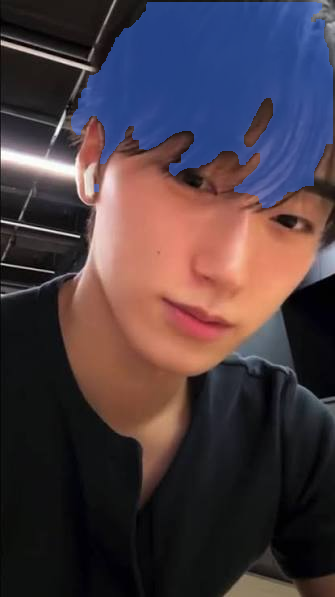

In [92]:
import numpy as np
from PIL import Image
from IPython.display import display

# 원본 이미지
original_rgb = np.array(img.convert("RGB"))
h, w = original_rgb.shape[:2]

# 기존 머리카락 마스크
final_hair_mask = after_mask.copy()

# 사진에서 눈 위치를 기준으로 제외 영역 만들기
yy, xx = np.mgrid[0:h, 0:w]
x = xx / w
y = yy / h

# 눈동자 주변 제외 영역 (사진에 맞춘 대략적인 위치)
eye1 = ((x - 0.58) / 0.06)**2 + ((y - 0.30) / 0.020)**2 <= 1

# 눈 영역은 염색하지 않기
final_hair_mask[eye1] = False

# 파란색 적용
preview = original_rgb.copy()
blue = np.array([60, 120, 255], dtype=np.float32)

preview[final_hair_mask] = (
    original_rgb[final_hair_mask].astype(np.float32) * 0.5
    + blue * 0.5
).astype(np.uint8)

display(Image.fromarray(preview))